# <span style="color:magenta">1. Setup and Config</span>

In [2]:
#import neccasary libraries
from pathlib import Path
import sys
root_dir = Path.cwd().parent
sys.path.append(str(root_dir))
import importlib

from src import custom_data as cd

Importing the necessary library:  
1. `torch`- it is framwork to do my whole project for deeplearning    
2. `nn`- for model architecture and other moduls  
3. `Path` - to determine current working directory which is important to link with other src files.
4. `sys` - it used to interact the Path library with the system to determine the current working directory.
5. `importlib`- for reloading src files.

### **1.1 Color configure**

In [3]:
#color configresion for printing
HEADER = '\033[95m'
ORANGE = '\033[38;5;208m'
OKBLUE = '\033[94m'
OKCYAN = '\033[96m'
OKGREEN = '\033[92m'
WARNING = '\033[93m'
FAIL = '\033[91m'
ENDC = '\033[0m'
BOLD = '\033[1m'
UNDERLINE = '\033[4m'

### **1.2 Device config**
Device agnostice are isential in deep learning pyTorch which speed up the speed of the computation to train the model.  befor we try to write the code i have to know which device(weather GPU if avialiable or CPU defualt device) i will use for my model. 

In [4]:
import torch

#device diagnostic code
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"{WARNING}Using device: {ENDC}{UNDERLINE}{device}{ENDC}")

Using device: cpu


### **1.3 Download the dataset**

In [5]:
import requests      #This is thired party library of python used to communicate with internet.
import zipfile       #This is thired party library of python used to work with zip files.
# Setup path to data folder
data_path = Path.cwd().parent / "Dataset" / "food_images"
image_path = data_path / "pizza_steak_sushi"

"""This if else block of code works for downloading the dataset. if the dataset directory there in my local computer the downloading is not necessary but if not the dataset will be download to the pointing place by creating the dirctory for the data."""

if image_path.is_dir():     #it is built in function of pathlib library to check if the directory is there or not.
    print(f"{image_path} directory exists.")
else:
    print(f"Did not find {image_path} directory, creating one...")
    image_path.mkdir(parents=True, exist_ok=True)
    
    # Download pizza, steak, sushi data
    with open(data_path / "pizza_steak_sushi.zip", "wb") as f:
        request = requests.get("https://github.com/mrdbourke/pytorch-deep-learning/raw/main/data/pizza_steak_sushi.zip")
        print("Downloading pizza, steak, sushi data...")
        f.write(request.content)

    # Unzip pizza, steak, sushi data
    with zipfile.ZipFile(data_path / "pizza_steak_sushi.zip", "r") as zip_ref:
        print("Unzipping pizza, steak, sushi data...") 
        zip_ref.extractall(image_path)


/home/nigatie/Documents/ML_DL/Deep_Learning/Dataset/food_images/pizza_steak_sushi directory exists.


In [6]:
import os
def walk_through_dir(dir_path):
  """
  Walks through dir_path returning its contents.
  Args:
    dir_path (str or pathlib.Path): target directory
  
  Returns:
    A print out of:
      number of subdiretories in dir_path
      number of images (files) in each subdirectory
      name of each subdirectory
  """
  for root_directory, directory_name, filenames in os.walk(dir_path):  #have tree like structure to access and organize the data structure.
    print(f"{root_directory} have {len(directory_name)} directories and {len(filenames)} files.")

### **1.4 Train/Test data**

In [ ]:
#set up the training and testing dataset
train_dir = image_path/"train"
test_dir = image_path/"test"


# walk through the training and testing directory
walk_through_dir(data_path.parent)     

/home/nigatie/Documents/ML_DL/Deep_Learning/Dataset have 1 directories and 0 files.
/home/nigatie/Documents/ML_DL/Deep_Learning/Dataset/food_images have 1 directories and 1 files.
/home/nigatie/Documents/ML_DL/Deep_Learning/Dataset/food_images/pizza_steak_sushi have 2 directories and 0 files.
/home/nigatie/Documents/ML_DL/Deep_Learning/Dataset/food_images/pizza_steak_sushi/test have 3 directories and 0 files.
/home/nigatie/Documents/ML_DL/Deep_Learning/Dataset/food_images/pizza_steak_sushi/test/pizza have 0 directories and 25 files.
/home/nigatie/Documents/ML_DL/Deep_Learning/Dataset/food_images/pizza_steak_sushi/test/sushi have 0 directories and 31 files.
/home/nigatie/Documents/ML_DL/Deep_Learning/Dataset/food_images/pizza_steak_sushi/test/steak have 0 directories and 19 files.
/home/nigatie/Documents/ML_DL/Deep_Learning/Dataset/food_images/pizza_steak_sushi/train have 3 directories and 0 files.
/home/nigatie/Documents/ML_DL/Deep_Learning/Dataset/food_images/pizza_steak_sushi/train/p

My dataset have 300 images. 225 for train dataset and 75 images for test dataset. specifically there some class imbalance but it is acceptable(the difference is small), pizza = 78 + 25 = 103, sushi = 31 + 72 = 103 and steak = 19 + 75 = 94 thus the total image of pizza and sushi exactly same(class ballanced) but steak are slightly smaller than both of the two datasets.

Random image path: /home/nigatie/Documents/ML_DL/Deep_Learning/Dataset/food_images/pizza_steak_sushi/test/steak/690177.jpg
Image class: steak
Image height: 512
Image width: 382


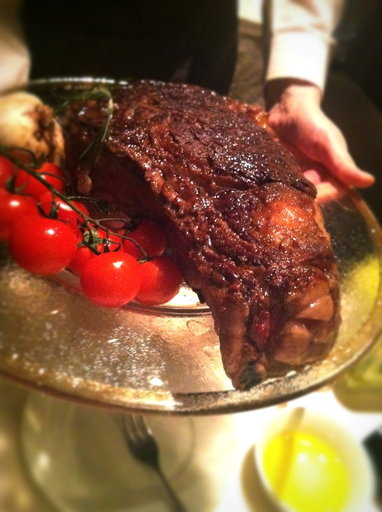

Random image path: /home/nigatie/Documents/ML_DL/Deep_Learning/Dataset/food_images/pizza_steak_sushi/test/steak/690177.jpg
Image class: steak
Image height: 512
Image width: 382


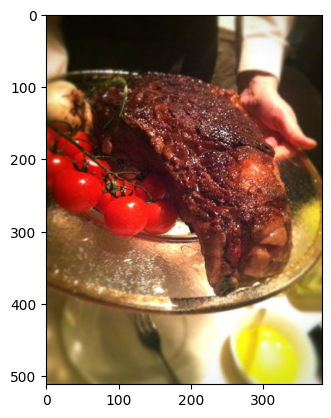

In [8]:
cd = importlib.reload(cd)

image_path_list = list(image_path.glob("*/*/*.jpg"))   #three depths of folders to get to the images
# image_path_list = list(image_path.glob("**/*.jpeg"))  #any depth of the folder are searched for jpeg images
image_diplay = cd.show_random_image(image_path_list)       

display(image_diplay)

#or i can do it like this using matplotlib
import matplotlib.pyplot as plt
import numpy as np
image = np.asarray(cd.show_random_image(image_path_list) )  #also show using matplotlib modul
plt.imshow(image)
plt.show()

# <span style="color:magenta">2. Transform the data</span>
Download, load and transform the dataset from torchvision module- torchvisioin are a parts of dataset module which contains only vision based datas.  
There are also other time of data from dataset module like torchaudio(audio datas), torchtext(text based datas).

In [9]:
#libraries
from torchvision import datasets, transforms
import random
from PIL import Image #to manupilate the image data.

<u>dataset</u>: is all about what data is load, and <u>dataloader</u>: are usfull for loading the data to train the model. The whole dataset are loaded to the model by batch. 

<span style="color:red">Transforming</span>: is preprocessing of data befor using for training the models. during transforming there are series of activities.   
1. resize the image - using transform.resize() all image size must the same for the model.
2. flip image ranodmly - transform.randomHorizontalFlip() - for data augmentation.
3. turn the image PIL(python image library)(pillow) image to tensor.   

`Image` are from PIL(in older version known as Python Image Library but now Pillow Library)  used to manipulate and process the image(open image, read image data, resize image data, convert color format, save the image)

In [10]:
#first transform the image
transform_image = transforms.Compose([
    #resize the image to 64 by 64
    transforms.Resize((64,64)),

    #flip image horizontally for data augmentation
    transforms.RandomHorizontalFlip(p=0.5),

    #then turn it into a tensor
    transforms.ToTensor()
])

There are some similarity between (k -are the number of element we want to randomly selected)
1. <span style="color:cyan">**random.choice(list)**</span>- have on parameters and return on random element from the list.
2. <span style="color:cyan">**ranodm.sample(list, k)**</span>- have two parameters and can return more than one element without replacment(no reapeat elements). 
3. <span style="color:cyan"> **ranodm.choices(list, k)**</span>- have also two parameters and can retun more than one element with replacment(one element may selected more than one).

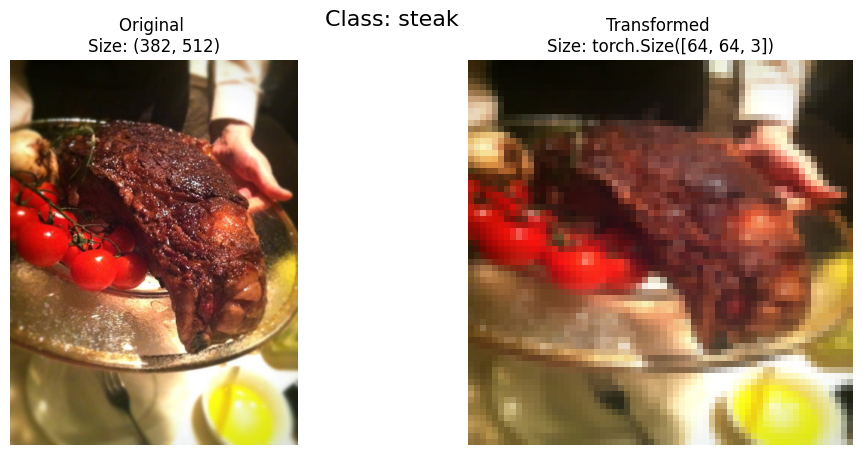

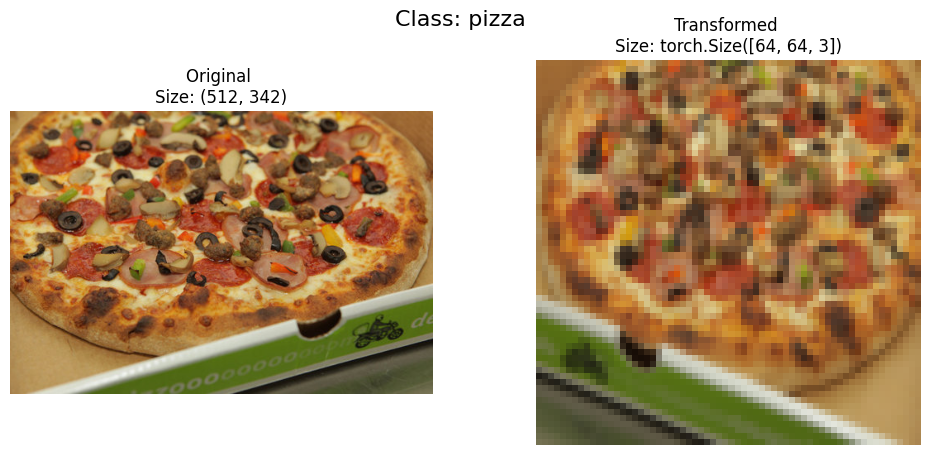

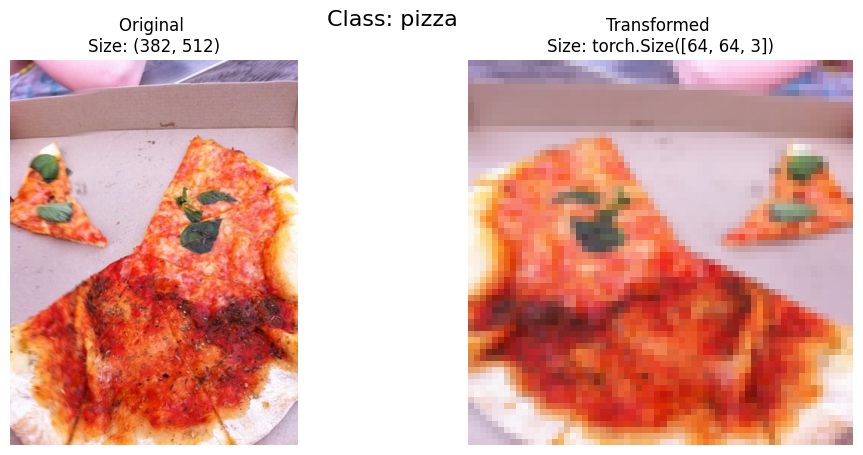

In [11]:
def plot_transformed_images(image_paths, transform, n=3, seed=42):

    random.seed(seed)
    
    random_image_paths = random.sample(image_paths, k=n)
    for image_path in random_image_paths:
        with Image.open(image_path) as f:
            fig, ax = plt.subplots(1, 2 , figsize=(12, 5))
            ax[0].imshow(f) 
            ax[0].set_title(f"Original \nSize: {f.size}")
            ax[0].axis("off")

            # Transform and plot image
            # Note: permute() will change shape of image to suit matplotlib 
            # (PyTorch default is [C, H, W] but Matplotlib is [H, W, C])
            transformed_image = transform(f).permute(1, 2, 0) 
            ax[1].imshow(transformed_image) 
            ax[1].set_title(f"Transformed \nSize: {transformed_image.shape}")
            ax[1].axis("off")

            fig.suptitle(f"Class: {image_path.parent.stem}", fontsize=16)

plot_transformed_images(image_path_list, 
                        transform=transform_image, 
                        n=3)

## <span style="color:magenta">3. Loading dataset</span>

<span style="color:red">ImageFolder: </span> are pyTorch function found it dataset module and it used for manipulation of datas(images) - transform image.  
-It loades image from folder, retun image and label, assign label based on folder.

### **3.1 setup the dataset using ImageFolder**

In [12]:
# Use ImageFolder to create dataset(s)
train_data = datasets.ImageFolder(root=train_dir,              # target folder of images
                                  transform=transform_image,   # transforms to perform on data (images)
                                  target_transform=None)       # transforms to perform on labels (if necessary)

test_data = datasets.ImageFolder(root=test_dir, 
                                 transform=transform_image)

print(f"Train data:\n{train_data}\nTest data:\n{test_data}")

Train data:
Dataset ImageFolder
    Number of datapoints: 225
    Root location: /home/nigatie/Documents/ML_DL/Deep_Learning/Dataset/food_images/pizza_steak_sushi/train
    StandardTransform
Transform: Compose(
               Resize(size=(64, 64), interpolation=bilinear, max_size=None, antialias=True)
               RandomHorizontalFlip(p=0.5)
               ToTensor()
           )
Test data:
Dataset ImageFolder
    Number of datapoints: 75
    Root location: /home/nigatie/Documents/ML_DL/Deep_Learning/Dataset/food_images/pizza_steak_sushi/test
    StandardTransform
Transform: Compose(
               Resize(size=(64, 64), interpolation=bilinear, max_size=None, antialias=True)
               RandomHorizontalFlip(p=0.5)
               ToTensor()
           )


From the above output:  
->train dataset have 225 images    
->test dataset have 75 images    
->one image are transformed to a size of <span style="color:orange">[height:64, width:64]</span> and randomly(half chance) horzontally fliped. 


Shape of Torch: torch.Size([3, 64, 64]) <--default format of PyTorch is [C, H, W]
Shape after permuted: torch.Size([64, 64, 3]) <--suitable for matplotlib [H, W, C]
Label: 0


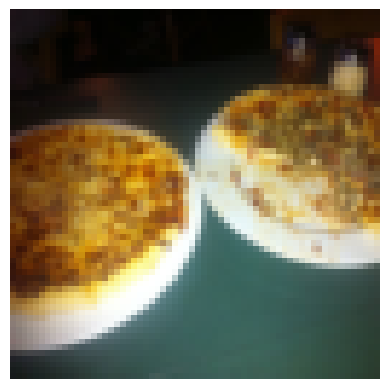

In [13]:
first_image = train_data[0][0]  #first element of the tuple is the image data and second element is the label
print(f"\nShape of Torch: {first_image.shape} <--default format of PyTorch is [C, H, W]")
image, label = train_data[0]
print(f"Shape after permuted: {image.permute(1, 2, 0).shape} <--suitable for matplotlib [H, W, C]")

"""permute are important here to change the shape of the image to suit matplotlib because PyTorch default is [C, H, W]-->[CHW or color_channel, height, width] but Matplotlib expectes [H, W, C]--> [height, width, color_channel], to be show the image using matplotlib the shape format should be [H, W, C] format."""
print(f"Label: {label}")
plt.imshow(image.permute(1, 2, 0))    
plt.axis("off")
plt.show()

In [14]:
class_name_array = train_data.classes
print(type(class_name_array))
print(class_name_array)


class_name_dic = train_data.class_to_idx
print(type(class_name_dic))
print(class_name_dic)

<class 'list'>
['pizza', 'steak', 'sushi']
<class 'dict'>
{'pizza': 0, 'steak': 1, 'sushi': 2}


In [15]:
img, label = train_data[0][0], train_data[0][1]
# print(f"Image tensor:\n{img}")
print(f"Image shape: {img.shape}")
print(f"Image datatype: {img.dtype}")
print(f"Image label: {label}")
print(f"Label datatype: {type(label)}")

Image shape: torch.Size([3, 64, 64])
Image datatype: torch.float32
Image label: 0
Label datatype: <class 'int'>


### **3.2 Load dataset Using dataloader**

<span style="color:orange">dataloader:</span> are a `torch.utils.data` library which used to load the dataset in to our code by wrapping into batchs.    
It is dataset sampler for the model.
Some arguments in dataloader:   
- <span style="color:cyan">dataset</span> – what data you want to load  
- <span style="color:cyan">batch_size</span> – number of images loaded in one cycle  
- <span style="color:cyan">shuffle (boolean)</span> – order randomness of the data  
- <span style="color:cyan">num_workers</span> – how many subprocesses to use for data loading

In [16]:
from torch.utils.data import DataLoader
#train data
train_dataloader = dataaloader = DataLoader(dataset=train_data, 
                                            batch_size=1, 
                                            num_workers=1,
                                            shuffle=True)

#Test data loader
test_dataloader = DataLoader(dataset=test_data, 
                             batch_size=1,
                             num_workers=1, 
                             shuffle=False)

### Load Image from custom dataset

In [17]:
#import libraries
import os
from typing import Tuple, Dict, List
import pathlib
from torch.utils.data import Dataset

In [18]:
#creating helper function to get class name

"""Objective to get: 
1. list of class name
2. dictionary of class name
3. class name indexing
"""

target_dir = train_dir
print(target_dir)

/home/nigatie/Documents/ML_DL/Deep_Learning/Dataset/food_images/pizza_steak_sushi/train


In [19]:
class_names = sorted([new.name for new in list(os.scandir(image_path/"train"))])
print(f"the target directory are: {target_dir}")
print(f"founded class name: {class_names}")

the target directory are: /home/nigatie/Documents/ML_DL/Deep_Learning/Dataset/food_images/pizza_steak_sushi/train
founded class name: ['pizza', 'steak', 'sushi']


In [20]:
#make custom function to get the class name in list and dictionary

def get_class(directory) ->Tuple[List[str], Dict[str, int]]:  #Type hinging (type annotation) used for better code readability and to help with debugging.

    classes = sorted(entry.name for entry in list(os.scandir(directory)) if entry.is_dir())

    #if there is not directory in the given path raise error
    if not classes:
        raise FileNotFoundError(f"Could't found any class in {directory}.")
    
    class_to_index = {cls_name: i for i, cls_name in enumerate(classes)}

    return classes, class_to_index

In [21]:
class_nam, class_dictionary = get_class(image_path/"train")
print(f"Class Name: {class_nam}, \nClass name with index: {class_dictionary}")

Class Name: ['pizza', 'steak', 'sushi'], 
Class name with index: {'pizza': 0, 'steak': 1, 'sushi': 2}


In [22]:
# 1. Subclass torch.utils.data.Dataset
class ImageFolderCustom(Dataset):    #manually representation of imageFolder class of PyTorch,
    
    # 2. Initialize with a targ_dir and transform (optional) parameter
    def __init__(self, targ_dir: str, transform=None) -> None:
        
        # 3. Create class attributes
        # Get all image paths
        self.paths = list(pathlib.Path(targ_dir).glob("*/*.jpg")) # note: you'd have to update this if you've got .png's or .jpeg's
        # Setup transforms
        self.transform = transform
        # Create classes and class_to_idx attributes
        self.classes, self.class_to_idx = get_class(targ_dir)

    # 4. Make function to load images
    def load_image(self, index: int) -> Image.Image:
        "Opens an image via a path and returns it."
        image_path = self.paths[index]
        return Image.open(image_path) 
    
    # 5. Overwrite the __len__() method (optional but recommended for subclasses of torch.utils.data.Dataset)
    def __len__(self) -> int:
        "Returns the total number of samples."
        return len(self.paths)
    
    # 6. Overwrite the __getitem__() method (required for subclasses of torch.utils.data.Dataset)
    def __getitem__(self, index: int) -> Tuple[torch.Tensor, int]:
        "Returns one sample of data, data and label (X, y)."
        img = self.load_image(index)
        class_name  = self.paths[index].parent.name # expects path in data_folder/class_name/image.jpeg
        class_idx = self.class_to_idx[class_name]

        # Transform if necessary
        if self.transform:
            return self.transform(img), class_idx # return data, label (X, y)
        else:
            return img, class_idx # return data, label (X, y)

In [ ]:
#now transform the prepared images 

#for train data
train_transform = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor()
])

#for test data(for test data we don't want to do data augmentation)
test_transform = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ToTensor()])

In [24]:
#now initialize the costom class for train and test data

train_data_custom = image_folder_custom = ImageFolderCustom(targ_dir=train_dir, 
                                                            transform=train_transform)
test_data_custom = ImageFolderCustom(targ_dir=test_dir,
                                    transform=test_transform)

In [40]:
# print(train_data_custom.classes, test_data_custom.class_to_idx)
print(len(train_data_custom) == len(train_data), "\n", len(test_data_custom) == len(test_data))
print(train_data_custom.classes == train_data.classes)

True 
 True
True


In [42]:
#about random.sample and random.choice() is selecting random sequence and random one element from the squence respectively.
    #random.choice() choose random single element from sequence
    #random.sample() choose random sequence of element from the sequence.

# 1. Take in a Dataset as well as a list of class names
def display_random_images(dataset: torch.utils.data.dataset.Dataset,
                          classes: List[str] = None,
                          n: int = 10,
                          display_shape: bool = True,
                          seed: int = None):
    
    # 2. Adjust display if n too high
    if n > 10:
        n = 10
        display_shape = False
        print(f"For display purposes, n shouldn't be larger than 10, setting to 10 and removing shape display.")
    
    # 3. Set random seed
    if seed:
        random.seed(seed)

    # 4. Get random sample indexes
    random_samples_idx = random.sample(range(len(dataset)), k=n)

    # 5. Setup plot
    plt.figure(figsize=(16, 8))

    # 6. Loop through samples and display random samples 
    for i, targ_sample in enumerate(random_samples_idx):
        targ_image, targ_label = dataset[targ_sample][0], dataset[targ_sample][1]

        # 7. Adjust image tensor shape for plotting: [color_channels, height, width] -> [color_channels, height, width]
        targ_image_adjust = targ_image.permute(1, 2, 0)

        # Plot adjusted samples
        plt.subplot(1, n, i+1)
        plt.imshow(targ_image_adjust)
        plt.axis("off")
        if classes:
            title = f"class: {classes[targ_label]}"
            if display_shape:
                title = title + f"\nshape: {targ_image_adjust.shape}"
        plt.title(title)